This notebook was created and can be run with the anaconda enviroment that can be downloaded [here](https://anaconda.org/la-koenig/ionq-qiskit1.1.2)

To set this up run: 
conda env create -f IonQ-qiskit1.1.2.yml

In [ ]:
#!conda env create -f IonQ-qiskit1.1.2-clean.yml

# Settings

In [5]:
#change this block to change data set
balanced = True
pca = "4"
percent = "0.25"

In [6]:
IonQcloud = False #True
IonQsimulator = True
statevector = True

FreshRun = True
Debugging = True 

In [7]:
#no diversification
#Nshots1 = 1000; Nshots2=100; num_qubits=4; 

# Diversification
Nshots1 = 490; Nshots2=100; num_qubits=int(pca); #SHould num_qubits be set to same as pca? 

In [8]:
# Hyperparameters
gamma = 0.69 #20.1 #IonQ used 0.5?
kappa = 8.7 #IonQ used 10

#I'm actually not sure if these are technically hyperparameters, but I'm going to call them that for now
num_splits = 10
fit_weight = 0.4

In [9]:
provider_string = "Replace With Your API Key Here"

# Preliminary

In [10]:
import numpy as np
import matplotlib.pyplot as plt #I don't use this but I don't want to remove it
import pandas as pd
import sklearn
from sklearn.metrics import confusion_matrix, accuracy_score #I'm not currently using accuracy_score but might later
from pathlib import Path
import time

from sklearn import svm
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold #I'm trying to switch from Suggle to Kfold

import datetime

#from qiskit import * #I don't like this line but I don't want to remove it yet.
from qiskit_aer import Aer #This was a drop in fix
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter


import seaborn as sns
import scipy as sp

In [11]:
from qiskit_ionq import IonQProvider
import json

if IonQcloud:
    provider = IonQProvider(provider_string)
    provider.backends()

In [12]:
provider = IonQProvider(provider_string)

if(IonQsimulator==True):
    if(IonQcloud==False):
        backend = Aer.get_backend('aer_simulator')
    if(IonQcloud==True):
        backend = provider.get_backend("ionq_simulator")    #The IonQ Cloud  Simulator
    if(statevector==True):   
        backend = Aer.get_backend('statevector_simulator')

elif (IonQsimulator==False):
    #backend = provider.get_backend("ionq_qpu")         
    backend = provider.get_backend("ionq_qpu.aria-1")  
    #backend = provider.get_backend("ionq_qpu.aria-2")  
    #backend = provider.get_backend("ionq_qpu.harmony")


backend.name


'statevector_simulator'

In [13]:
nameString = "_" + pca +"PCA_"

if balanced:
    nameString += "balanced_"
else:
    nameString += "unbalanced_"

nameString += percent + "percent"

nameString

'_4PCA_balanced_0.25percent'

In [14]:
if Debugging:
    run = "_debug"
else:
    if IonQsimulator:
        run = "_" + datetime.datetime.now().strftime("%Y-%m-%d_%H-%M") + "__" + backend.name + nameString
    else:
        run = "_" + datetime.datetime.now().strftime("%Y-%m-%d_%H-%M") + "__" + backend.name() + nameString

run

'_debug'

# Functions

In [15]:
def mcc_score(c1):
    n1 = c1[0, 0] + c1[0, 1]
    n2 = c1[1, 0] + c1[1, 1]
    n3 = c1[0, 0] + c1[1, 0]
    n4 = c1[0, 1] + c1[1, 1]
    #print(n1, n2, n3, n4)
    return (c1[0, 0] * c1[1, 1] - c1[0, 1] * c1[1, 0]) / np.sqrt(n1 * n2 * n3 * n4)

In [16]:
def rbs(qc, i,j,theta):

    qc.h(i)
    qc.h(j)
    qc.cz(i,j)
    qc.ry(theta/2.0,i)
    qc.ry(-theta/2.0,j)
    qc.cz(i,j)
    qc.h(i)
    qc.h(j)

In [17]:
def create_rbs_circuit_x(num_qubits,x_point):

    qc = QuantumCircuit(num_qubits+1)


    iter = 0;
    for x in range(2):
        for j in range(int(np.log2(num_qubits))):

            n = int(num_qubits/(2**(j+1)));

            for i in range(n):

                for k in range(int(2**j)):

                    theta1 = Parameter(f"0{iter}")
                    iter +=1

                    rbs(qc,1+i+k*n*2,1+i+k*n*2+n,theta1)


        for i in range(int(num_qubits/2)):

            theta1 = Parameter(f"0{iter}")
            iter +=1
            rbs(qc,1+2*i,1+2*i+1,theta1*x_point[2*i])


        for i in range(int(num_qubits/2)):

            theta1 = Parameter(f"0{iter}")
            iter +=1
            rbs(qc,1+2*i+1,1+(2*i+2)%num_qubits,theta1*x_point[2*i+1])
    
    return qc

In [18]:
# The circuit used to calculate both the sign and amplitude of inner product
def extended_unary_enc(x_data):
   
    qc_data = [];
    for i in range(len(x_data)):
        
        qc = QuantumCircuit(len(x_data[0])+1)

        values = x_data[i];

        d=len(values)
        d2=int(len(values)/2)
        r=[0]*(d-1)
        angle=[0]*d


        for j in range(1,d2+1):
            r[d2+j-2] = (values[2*j-1]**2.0 + values[2*j-1-1]**2.0)**0.5+1e-10;

        for j in range(d2-1,0,-1):
            r[j-1] = (r[2*j]**2.0 + r[2*j-1]**2.0)**0.5 + 1e-10

        for j in range(1,d2+1):
            if(values[2*j-1]>0):
                angle[d2+j-2] = np.arccos(values[2*j-2]/r[d2+j-2]);
            else:
                angle[d2+j-2] = 2*np.pi - np.arccos(values[2*j-2]/r[d2+j-2]);

        for j in range(1,d2):
            angle[j-1] = np.arccos(r[2*j-1]/r[j-1]);

        qc.x(0)
        rbs(qc,0,1,np.pi/2)
        for j in range(int(np.log2(d))):
            for k in range(2**j):
                s1 = d/(2**j)*k
                s2 = d/(2**(j+1))
                #iRBS(circuit, int(s1), int(s1+s2), angle[2**(j)+k-1])
                rbs(qc, int(s1)+1, int(s1+s2)+1, angle[2**(j)+k-1]*2.0)
                #circuit.exappend(cirq.ops.PhasedFSimGate(angle[2**j +k-1],chi=np.pi/2.0).on(qubits[int(s1)],qubits[int(s1+s2)]))

                
        qc_data.append(qc)
        
    return qc_data

In [19]:
def generate_quantum_vec_QPU_send(qc_data, variational_params, 
                                  Nshots1, Nshots2, num_qubits, backend,
                                  path):

    path = Path("./run" + path)
    
    circs_all = []
    job_ids = []
    jobs_all = []
    #time = time.time()

    job_size = 150 #I used 1000 for 4PCA but that is too big for 8PCA


    for i in range(len(qc_data)):
        #print("top of loop time: ", time.time())

        str1 = format(1,'0'+str(num_qubits+1)+'b')
        qc1 = qc_data[i].copy()
        circ1 = qc1
        circ1.measure_all()
        circ1 = circ1.assign_parameters(variational_params)

        circs_all.append(circ1)
  
        #This portions determines the sign of the input
        for j in range(num_qubits):
            qc0 = QuantumCircuit(num_qubits+1)
            qc0.h(0)
            qc0.h(j+1)

            qc1 = qc_data[i].copy()
            circ1 = qc1.compose(qc0)
            circ1.measure_all()
            circ1 = circ1.assign_parameters(variational_params)

            circs_all.append(circ1)
            
# multi circuit job submission
    print("Number of circuits: ", len(circs_all))
    hold_index = (len(circs_all)%job_size)

    for i in range(job_size, len(circs_all), job_size):
        print(i)
        circ_submit = circs_all[i-job_size:i]
        print("Number of circuits in this job: ", len(circ_submit))
        #try:
        if(IonQsimulator == True):
            job = backend.run(circ_submit, shots = Nshots1)
        elif(IonQsimulator == False):
            job = backend.run(circ_submit, shots = Nshots1,
                            job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
        # except Exception as e:
        #     working = False
        #     work_count = 0
        #     while not working or work_count < 10:
        #         try:
        #             if(IonQsimulator == True):
        #                 job = backend.run(circ_submit, shots = Nshots1)
        #             elif(IonQsimulator == False):
        #                 job = backend.run(circ_submit, shots = Nshots1,
        #                             job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
        #             working = True
        #         except Exception as e:
        #             print(e)
        #             print("Error: trying again")
        #             if(IonQsimulator == True):
        #                 job = backend.run(circ_submit, shots = Nshots1)
        #             elif(IonQsimulator == False):
        #                 job = backend.run(circ_submit, shots = Nshots1,
        #                             job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
        #             working = False
        #             time.sleep(5)
        #             work_count += 1
        
        jobs_all.append(job)

    print("Number of circuits in last job: ", len(circs_all[-hold_index:]))
    # try:
    if(IonQsimulator == True):
        job = backend.run(circs_all[-hold_index:], shots = Nshots1)
    elif(IonQsimulator == False):
        job = backend.run(circs_all[-hold_index:], shots = Nshots1,
                        job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
            
    # except Exception as e:
    #     working = False
    #     work_count = 0
    #     while not working or work_count < 10:
    #         try:
    #             if(IonQsimulator == True):
    #                 job = backend.run(circs_all[-hold_index:], shots = Nshots1)
    #             elif(IonQsimulator == False):
    #                 job = backend.run(circs_all[-hold_index:], shots = Nshots1,
    #                           job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
    #             working = True
    #         except Exception as e:
    #             print(e)
    #             print("Error: trying again")
    #             if(IonQsimulator == True):
    #                 job = backend.run(circs_all[-hold_index:], shots = Nshots1)
    #             elif(IonQsimulator == False):
    #                 job = backend.run(circs_all[-hold_index:], shots = Nshots1,
    #                           job_settings={ "diversification": {"type":"qubit-map","aggregationType":"average"}})
    #             working = False
    #             time.sleep(5)
    #             work_count += 1
    jobs_all.append(job)
    
    if  not IonQcloud:
        job_ids = jobs_all
    else:
        for job in jobs_all:
            job_ids.append(job.job_id())
        print(job_ids)

        #save job_ids for this iteration to a file
        print(path)
        fname1= Path(path / "job_ids")
        print(fname1)
        fname1.mkdir(parents=True, exist_ok=True)
        with open(fname1 / "jobs.txt", 'w') as f:
            for line in job_ids:
                f.write(f"{line}\n")

   
    return job_ids               

def generate_quantum_vec_QPU_receive(job_ids, qc_data, 
                                     Nshots1, Nshots2, num_qubits, backend):
    job_count = 0;
    qc=[]
    hist_all = []
    vec_sign = np.zeros(num_qubits+1);
    vec_sign[0] = 1

    vec_abs = np.zeros(num_qubits+1)
    results_all = []

    for id in job_ids:
        if IonQcloud:
            try:
                result = backend.retrieve_job(id).result().get_counts()
                #print(results_all)
            except Exception as e:
                working = False
                work_count = 0
                while not working or work_count < 10:
                    try:
                        result = backend.retrieve_job(id).result()
                        working = True
                    except Exception as e:
                        print(e)
                        print(id, " IonQAPIError: trying again")
                        working = False
                        time.sleep(5)
                        work_count += 1
        else:
            result = id.result().get_counts()
        results_all.append(result)

    print('len of results: ', len(results_all))
    results_all = [j for sub in results_all for j in sub]
    print('len of results: ', len(results_all))

    #below this is mostly IonQ code

    for i in range(len(qc_data)):
        
        result = results_all[job_count]

        hist_all.append(result)
        job_count += 1;
        
        for k in range(num_qubits+1):
            str1 = format(2**k,'0'+str(num_qubits+1)+'b')
            if(str1 in result):
                vec_abs[k] = np.sqrt(result[str1]/Nshots1)
            else:
                vec_abs[k] = 0.0
                
            
        
        for j in range(num_qubits):

            result = results_all[job_count]
            
            hist_all.append(result)
            job_count += 1;
            
            str0 = format(0,'0'+str(num_qubits+1)+'b')
            str1 = format(1,'0'+str(num_qubits+1)+'b')
            str_j = format(2**(j+1),'0'+str(num_qubits+1)+'b')
            if(str0 in result):
                apb1 = result[str0]/Nshots2
            else:
                apb1 = 0;
            if(str1 in result):
                amb1 = result[str1]/Nshots2
            else:
                amb1 = 0;

            if(str_j in result):  
                amb2 = result[str_j]/Nshots2
            else:
                amb2 = 0;
           
            if(apb1 >= 0.5*(amb1+amb2)):
                vec_sign[j+1] = 1
            elif(apb1 < 0.5*(amb1+amb2)):
                vec_sign[j+1] = -1
        
        
        qc.append(np.multiply(vec_abs,vec_sign))

    return qc, job_ids

In [20]:
#This takes the quantum data and calculates the gram matrix
def measure_unary_kernel(qc_vec, x_data, qc_test_vec, x_test, test, gamma):
    
    gram_mat = np.zeros((len(x_data),len(x_test)))
    
    x_norm = []
    for i in range(len(x_data)):
        x_norm.append(np.linalg.norm(x_data[i]))
    x_test_norm = []
    for i in range(len(x_test)):
        x_test_norm.append(np.linalg.norm(x_test[i]))
    
    
    for i in range(len(x_data)):
                   
        if(test==True):
            jstart = 0
        else:
            jstart = i+1
                   
        for j in range(jstart,len(x_test)):
            
            inner = 2.0*(np.abs(np.dot(qc_vec[i],qc_test_vec[j]))-0.5)
            output = x_norm[i]**2.0 + x_test_norm[j]**2.0 - 2.0*inner*x_norm[i]*x_test_norm[j]

            gram_mat[i,j] = np.exp(-1.0*gamma*output);

    if(test==False):
        for i in range(len(x_data)):
                   
            gram_mat[i,i] = 1.0
            for j in range(i):
                gram_mat[i,j] = gram_mat[j,i]
    
     
    return gram_mat


In [21]:
def run_svm(variational_parmas, 
            qc_data_train, x_train, y_train,
            qc_data_test, x_test, y_test,
            backend,
            filepath, 
            training = True,
            qc_data_val = None, x_val = None, y_val = None, validation = False):
    
    
    #print(x_train)
    # First we will get the quantuam circuts 
    if training:
        qc_transform_train = []
        for i in range(len(qc_data_train)):
            circ = qc_data_train[i]
            # print(circ)
            result = backend.run(circ.assign_parameters(variational_parmas),shots = 1).result()
            qc_transform_train.append(result.get_statevector())

        qc_transform_test = []
        for i in range(len(qc_data_test)):
            circ = qc_data_test[i]
            result = backend.run(circ.assign_parameters(variational_parmas),shots = 1).result()
            qc_transform_test.append(result.get_statevector())

        if validation:
            qc_transform_val = []
            for i in range(len(qc_data_val)):
                circ = qc_data_val[i]
                result = backend.run(circ.assign_parameters(variational_parmas),shots = 1).result()
                qc_transform_val.append(result.get_statevector())
            
    else:
        #will have to set up logging and saving of ids
        job_ids_train = generate_quantum_vec_QPU_send(qc_data_train, variational_parmas,
                                                Nshots1, Nshots2, num_qubits, backend,
                                                filepath)
        qc_transform_train, job_ids_train_data = generate_quantum_vec_QPU_receive(job_ids_train, qc_data_train, 
                                                                        Nshots1, Nshots2, num_qubits, backend)
    
        job_ids_test = generate_quantum_vec_QPU_send(qc_data_test, variational_parmas,
                                                Nshots1, Nshots2, num_qubits, backend,
                                                filepath)
        qc_transform_test, job_ids_test_data = generate_quantum_vec_QPU_receive(job_ids_test, qc_data_test, 
                                                                        Nshots1, Nshots2, num_qubits, backend)
    
        if validation:
            job_ids_val = generate_quantum_vec_QPU_send(qc_data_val, variational_parmas,
                                                    Nshots1, Nshots2, num_qubits, backend,
                                                    filepath)
            qc_transform_val, job_ids_val_data = generate_quantum_vec_QPU_receive(job_ids_val, qc_data_val, 
                                                                            Nshots1, Nshots2, num_qubits, backend)
    # get the gram matrices for training and predicting
    gram_train = measure_unary_kernel(qc_transform_train, x_train, qc_transform_train, x_train, 
                                    False, gamma)
    gram_test = measure_unary_kernel(qc_transform_train, x_train, qc_transform_test, x_test, 
                                    True, gamma)
    if validation:
        gram_val = measure_unary_kernel(qc_transform_train, x_train, qc_transform_val, x_val, 
                                    True, gamma)
    
    #print(gram_train)
    
    # Train the SVM
    clf = svm.SVC(kernel='precomputed', class_weight='balanced')
    clf.fit(gram_train, y_train)    

    y_pred_train = clf.predict(gram_train)
    y_pred_test = clf.predict(gram_test.T)
    if validation:
        y_pred_val = clf.predict(gram_val.T)

    if validation:
        return y_pred_train, y_pred_test, y_pred_val
    else:
        return y_pred_train, y_pred_test


# data

In [22]:
path = Path("../Data") #will have to fix this when I  get new data

In [23]:
X = pd.read_csv(path / ("X" + nameString + ".csv"))
y = pd.read_csv(path / ("y" + nameString + ".csv"))
X.shape, y.shape


((86, 4), (86, 1))

In [24]:
y.value_counts()

Label
False    43
True     43
Name: count, dtype: int64

In [25]:
#convert to int labels
y1 = 1 - y

#1 is false and 0 is true
print(y1.shape)  

X1 = X #idk really
X1[0:1]


(86, 1)


,PCA1,PCA2,PCA3,PCA4
0,-0.333071,-0.659421,0.614187,-0.121644


In [26]:
y1.value_counts()
#number of failures in the dataset

Label
0        43
1        43
Name: count, dtype: int64

In [27]:
y1 = y1.to_numpy()

#### Load data into quantum circuits

So I do this before splitting as apposed to after making all my splits. This is notable in it's difference from the way that IonQ did it but I can't come up with a reason to do it their way and this was smoother for my brian.

In [28]:
# First load the data into amplitutde encoded wavefunctions
x_data = X1.values
X_qc_enc = extended_unary_enc(x_data)

#next we need to normalize the data
x_data_norm = []
for x in x_data:
    x_data_norm.append(x / np.linalg.norm(x))

# Finally we need to create the variation rbs circuit and append that to the encoding circuit
X_qc_variational = []
for i in range(len(X_qc_enc)):
    var_circuit = create_rbs_circuit_x(X_qc_enc[0].width() - 1, x_data_norm[i])
    circ = X_qc_enc[i].compose(var_circuit)
    X_qc_variational.append(circ)

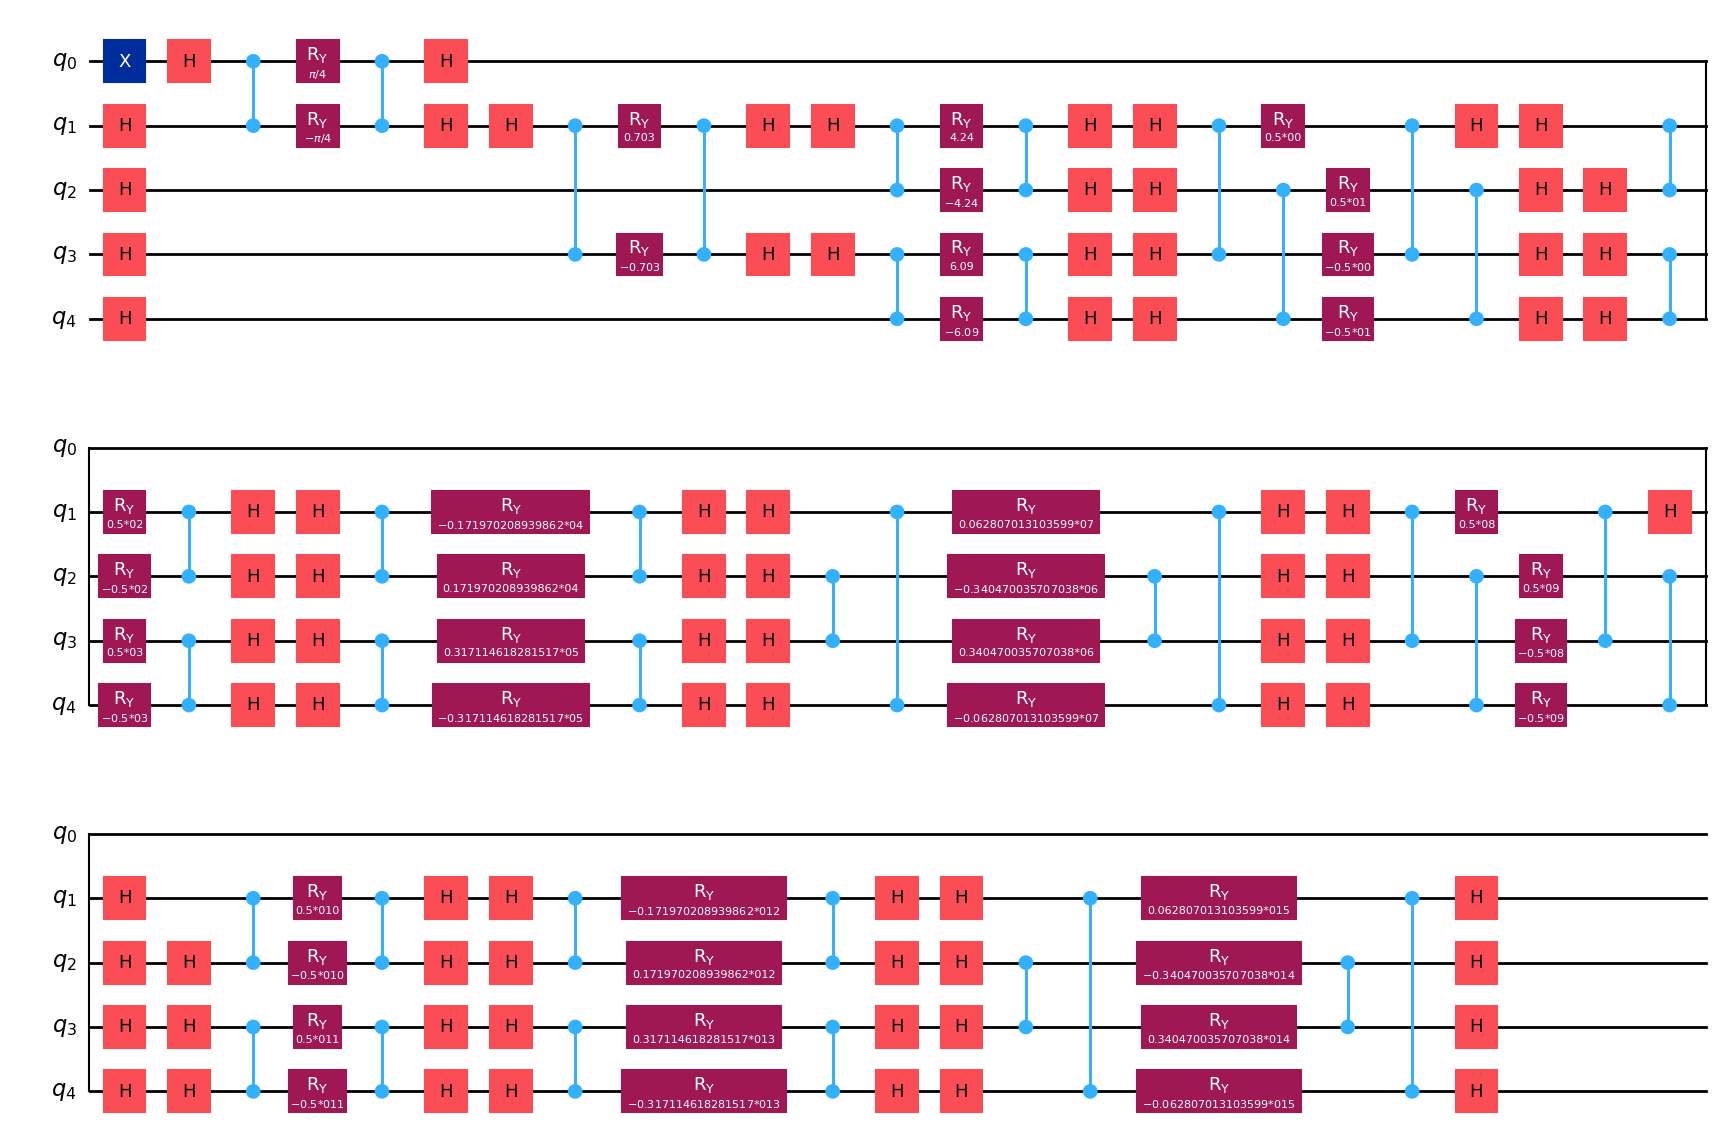

In [29]:
X_qc_variational[0].draw(output="mpl")

In [30]:
n_splits = num_splits
n_reps = 1

stats = []

splitter = StratifiedShuffleSplit(n_splits=1, test_size=(0.3/1.3)) #, random_state=i)
a = [*splitter.split(x_data, y1)] #indices of splits
    
Xa, ya = x_data[a[0][0]], y1[a[0][0]] #training
Xb, yb = x_data[a[0][1]], y1[a[0][1]] #validation

X_qc_train = [X_qc_variational[i] for i in a[0][0]]
X_qc_val = [X_qc_variational[i] for i in a[0][1]]

splitter = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.3) #, random_state=i)

a = [*splitter.split(Xa, ya)]
    
print("train size = ", len(ya[a[0][0]]), 
    " test size = ", len(ya[a[0][1]]),
        " val size = ", len(yb))

#ya[a[0][0]].value_counts(), ya[a[0][1]].value_counts(), yb.value_counts()
print("train failures: ", sum(ya[a[0][0]]), " test failures: ", sum(ya[a[0][1]]), " val failures: ", sum(yb))

train size =  46  test size =  20  val size =  20
train failures:  [23]  test failures:  [10]  val failures:  [10]


# Training and optimization of the quantum kernel

1. Create function for kernel optimization (cost function)
    - This should create the quantum circuts, get a gram matrix, and then run the svm training/testing 
    - Needs to have initial parameters for kernel fed into it
    - log everything (might need a logger? they made a class but tbd if I wanna do that)
2. There might be value in making/adding the saving of job-ids/data points as a function (either addding it whereever circuits get run or as it's own function)
3. Run the optimization with K-fold cross validation (this is different from them)


In [31]:
# This section is done with a local simulator

if(IonQcloud==False):
    backend = Aer.get_backend('aer_simulator')
if(IonQcloud==True):
    backend = provider.get_backend("ionq_simulator")    #The IonQ Cloud  Simulator

if(statevector==True):   
    backend = Aer.get_backend('statevector_simulator')

backend.name


'statevector_simulator'

In [32]:
def cost(params, 
        qc_data, x_data, y_data,
        qc_val, x_val_list, y_val_list,
        train_split, #val_split,
        backend, run, stats, training = True):
    
    global iteration
    iteration += 1
    
    #split the data into training and testing sets
    n_splits = len(train_split)
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True)#, random_state=i)

    mcc_train_fit = np.zeros(n_splits)
    mcc_train_pred = np.zeros(n_splits) #This is actually another training set
    mcc_val = np.zeros(n_splits)
    mcc_classical = np.zeros(n_splits)

    savings_train_fit = np.zeros(n_splits)
    savings_train_pred = np.zeros(n_splits)
    savings_val = np.zeros(n_splits)
    savings_classical = np.zeros(n_splits)

    splitter = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.3)
    j = 0
    for train_fit_index, train_pred_index in train_split: 
    #for train_fit_index, train_pred_index in splitter.split(x_data, y_data):
        print('.', end='')
        X_qc_train_fit = [qc_data[i] for i in train_fit_index]
        X_qc_train_pred = [qc_data[i] for i in train_pred_index]
        X_qc_val = qc_val#[qc_val[i] for i in val_split[j][0]]
        
        x_train_fit, x_train_pred = x_data[train_fit_index], x_data[train_pred_index]
        y_train_fit, y_train_pred = y_data[train_fit_index], y_data[train_pred_index]
        x_val, y_val = x_val_list, y_val_list #x_val_list[val_split[j][0]], y_val_list[val_split[j][0]]

        y_train_fit = np.ravel(y_train_fit)
        y_train_pred = np.ravel(y_train_pred)
        y_val = np.ravel(y_val)

        # Now you need to run the SVM
        y_pred_train, y_pred_test, y_pred_val = run_svm(params, 
                                                        X_qc_train_fit, x_train_fit, y_train_fit,
                                                        X_qc_train_pred, x_train_pred, y_train_pred, 
                                                        backend, run, training,
                                                        X_qc_val, x_val, y_val, validation = True)
    
        clf = svm.SVC(kernel='rbf', gamma=gamma, class_weight='balanced')
        clf.fit(x_train_fit, y_train_fit)
        y_pred_classical = clf.predict(x_val)
    
        for t in [["train_fit", y_pred_train, y_train_fit, mcc_train_fit, savings_train_fit], 
                ["train_pred", y_pred_test, y_train_pred, mcc_train_pred, savings_train_pred],
                ["val", y_pred_val, y_val, mcc_val, savings_val],
                ["classical", y_pred_classical, y_val, mcc_classical, savings_classical]]:
            
            confusion = confusion_matrix(t[2], t[1], normalize='true')

            mcc = mcc_score(confusion)
            t[3][j] = mcc

            n_base = confusion[0,1] + confusion[1,1]
            # n_base = confusion[1,0] + confusion[1,1]
            savings = kappa * (confusion[1,0] - n_base) + confusion[0,1]

            t[4][j] = savings

        j += 1

    for t in [["train_fit", mcc_train_fit, savings_train_fit], 
            ["train_pred", mcc_train_pred, savings_train_pred],
            ["val", mcc_val, savings_val],
            ["classical", mcc_classical, savings_classical]]:
            
        dict = {'phase': t[0],
                'mcc': t[1].mean(),
                'savings': t[2].mean(),
                'gamma': gamma,
                'iteration': iteration,}

        stats.append(dict)
    
    #print("train: ", savings_train.mean(), " test: ", savings_test.mean(), " val: ", savings_val.mean())
    #print("train: ", stats[-3]['savings'], " test: ", stats[-2]['savings']) 
    
    cost = savings_train_fit.mean() * fit_weight + savings_train_pred.mean()
    #cost = - mcc_train_fit.mean() - fit_weight * mcc_train_pred.mean()
    #really not sure about this either but again, this part is all directly from the other code.

    print(f"Iteration {iteration} Cost: {cost} MCC: {mcc_val.mean()} Savings: {savings_val.mean()}")
    

    return cost

In [33]:
num_params = X_qc_variational[0].num_parameters;

initiale_params = np.random.rand(num_params)

num_params

16

In [34]:

num_it = 50

n_splits = num_splits
n_reps = 1

stats = []

for i in range(1):
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=(0.3/1.3)) #, random_state=i)
    a = [*splitter.split(x_data, y1)] #indices of splits
    
    Xa, ya = x_data[a[0][0]], y1[a[0][0]] #training
    Xb, yb = x_data[a[0][1]], y1[a[0][1]] #validation

    X_qc_train = [X_qc_variational[i] for i in a[0][0]]
    X_qc_val = [X_qc_variational[i] for i in a[0][1]]

    splitter = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.3) #, random_state=i)

    a = [*splitter.split(Xa, ya)]
    
    print("train size = ", len(ya[a[0][0]]), 
        " test size = ", len(ya[a[0][1]]),
            " val size = ", len(yb))

    args = (X_qc_train, Xa, ya, 
            X_qc_val, Xb, yb,
            a, 
            backend, run, stats)
    
    for j in range(n_reps):
        #np.random.seed(i*10 + j)
        initiale_params = np.random.uniform(0, 2*np.pi, num_params) #np.random.rand(num_params)
        print("initiale_params = ", initiale_params)
        iteration = 0
        opt_result = sp.optimize.minimize(cost, initiale_params, args=args, 
                                          #method='COBYQA', options={'maxiter':num_it},
                                          method='COBYLA', options={'maxiter':num_it, 'tol':0},#'disp':True})
                                          bounds = sp.optimize.Bounds(0, 2*np.pi))

train size =  46  test size =  20  val size =  20
initiale_params =  [5.02838019 3.23016813 3.09697594 5.05780905 4.32039617 3.72891996
 0.29518642 5.20435033 0.46807647 5.05198209 0.87379297 3.93201285
 4.18763608 5.5197787  6.01418916 5.99861153]
..........Iteration 1 Cost: -11.715608695652172 MCC: 0.6426478318421589 Savings: -7.205
..........Iteration 2 Cost: -10.840782608695651 MCC: 0.6847099044581247 Savings: -7.399000000000001
..........Iteration 3 Cost: -11.996130434782607 MCC: 0.6533121371283126 Savings: -7.127999999999998
..........Iteration 4 Cost: -11.822521739130433 MCC: 0.6821158824088691 Savings: -6.897
..........Iteration 5 Cost: -12.23413043478261 MCC: 0.6635640278912731 Savings: -6.8
..........Iteration 6 Cost: -11.356782608695653 MCC: 0.6163180958527466 Savings: -7.435999999999998
..........Iteration 7 Cost: -12.174000000000001 MCC: 0.6941181875697866 Savings: -7.071
..........Iteration 8 Cost: -11.82591304347826 MCC: 0.6917632353407243 Savings: -7.071
..........Itera

In [35]:
stats_df = pd.DataFrame(stats)
# stats_df['iteration'] = stats_df.index
stats_df

,phase,mcc,savings,gamma,iteration
0,train_fit,0.820941,-9.266522,0.69,1
1,train_pred,0.353696,-8.009000,0.69,1
2,val,0.642648,-7.205000,0.69,1
3,classical,0.553482,-7.145000,0.69,1
4,train_fit,0.814325,-8.426957,0.69,2
...,...,...,...,...,...
195,classical,0.553482,-7.145000,0.69,49
196,train_fit,0.844805,-9.065652,0.69,50
197,train_pred,0.431131,-9.227000,0.69,50
198,val,0.644701,-6.452000,0.69,50


In [36]:
stats_df[stats_df['phase'] == 'val'].drop(columns=['phase']).groupby('iteration').mean()


,mcc,savings,gamma
iteration,,,
1,0.642648,-7.205,0.69
2,0.684710,-7.399,0.69
3,0.653312,-7.128,0.69
4,0.682116,-6.897,0.69
5,0.663564,-6.800,0.69
6,0.616318,-7.436,0.69
7,0.694118,-7.071,0.69
8,0.691763,-7.071,0.69
9,0.673312,-6.974,0.69


In [37]:
stats_stdv = stats_df.groupby(['phase', 'gamma', 'iteration']).describe(percentiles=[0.95])
stats_stdv

mcc                                              \
                          count      mean std       min       50%       95%   
phase     gamma iteration                                                     
classical 0.69  1           1.0  0.553482 NaN  0.553482  0.553482  0.553482   
                2           1.0  0.553482 NaN  0.553482  0.553482  0.553482   
                3           1.0  0.553482 NaN  0.553482  0.553482  0.553482   
                4           1.0  0.553482 NaN  0.553482  0.553482  0.553482   
                5           1.0  0.553482 NaN  0.553482  0.553482  0.553482   
...                         ...       ...  ..       ...       ...       ...   
val       0.69  46          1.0  0.673312 NaN  0.673312  0.673312  0.673312   
                47          1.0  0.654669 NaN  0.654669  0.654669  0.654669   
                48          1.0  0.644701 NaN  0.644701  0.644701  0.644701   
                49          1.0  0.653816 NaN  0.653816  0.653816  0.653816   
                50          1.0  0.644701 NaN  0.644701  0.644701  0.644701   

                                    savings                                  \
                                max   count   mean std    min    50%    95%   
phase     gamma iteration                                                     
classical 0.69  1          0.553482     1.0 -7.145 NaN -7.145 -7.145 -7.145   
                2          0.553482     1.0 -7.145 NaN -7.145 -7.145 -7.145   
                3          0.553482     1.0 -7.145 NaN -7.145 -7.145 -7.145   
                4          0.553482     1.0 -7.145 NaN -7.145 -7.145 -7.145   
                5          0.553482     1.0 -7.145 NaN -7.145 -7.145 -7.145   
...                             ...     ...    ...  ..    ...    ...    ...   
val       0.69  46         0.673312     1.0 -6.974 NaN -6.974 -6.974 -6.974   
                47         0.654669     1.0 -6.626 NaN -6.626 -6.626 -6.626   
                48         0.644701     1.0 -6.452 NaN -6.452 -6.452 -6.452   
                49         0.653816     1.0 -6.626 NaN -6.626 -6.626 -6.626   
                50         0.644701     1.0 -6.452 NaN -6.452 -6.452 -6.452   

                                  
                             max  
phase     gamma iteration         
classical 0.69  1         -7.145  
                2         -7.145  
                3         -7.145  
                4         -7.145  
                5         -7.145  
...                          ...  
val       0.69  46        -6.974  
                47        -6.626  
                48        -6.452  
                49        -6.626  
                50        -6.452  

[200 rows x 14 columns]

Text(0.5, 1.0, 'Cost over Iterations for  4PCA balanced 0.25percent')

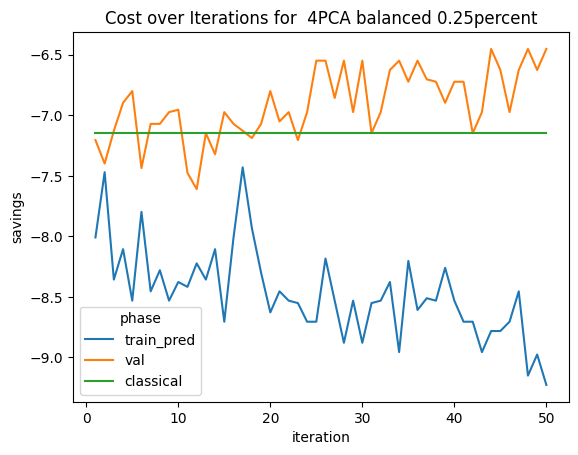

In [38]:
data = stats_df[stats_df['phase'] != 'train_fit']

ax = sns.lineplot(data=data, x='iteration', y='savings', hue='phase')
ax.set_title('Cost over Iterations for ' + nameString.replace("_", " "))

Text(0.5, 1.0, 'mcc over Iterations for 4PCA balanced 0.25percent')

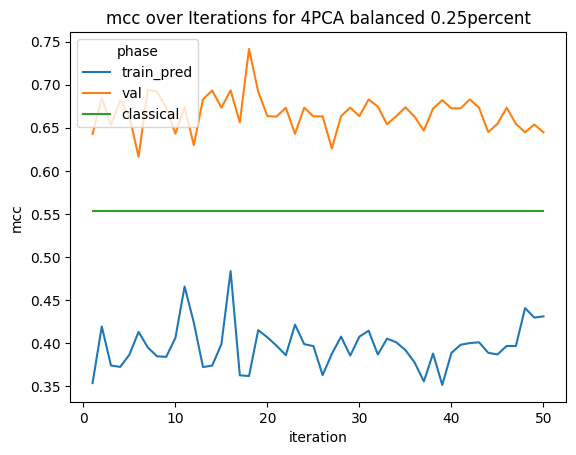

In [39]:
data = stats_df[stats_df['phase'] != 'train_fit']

ax = sns.lineplot(data=data, x='iteration', y='mcc', hue='phase')
ax.set_title('mcc over Iterations for' + nameString.replace("_", " "))


# Running the quantum SVM

This section should take the parameters found in the last section and run the svm training and testing protocol. This is just to get a final configuration of the SVM. (I'm not convinced this training part is necisary and can't be taken from the end of the optimization loop.) This will def be validated on data that was withheld initially.

In [40]:
provider = IonQProvider(provider_string)

if(IonQsimulator==True):
    backend = provider.get_backend("ionq_simulator")    
elif (IonQsimulator==False):
    #backend = provider.get_backend("ionq_qpu")         
    backend = provider.get_backend("ionq_qpu.aria-1")  
    #backend = provider.get_backend("ionq_qpu.aria-2")  
    #backend = provider.get_backend("ionq_qpu.harmony")

backend.name()


'ionq_simulator'

In [41]:
IonQsimulator

True

In [42]:
if(IonQsimulator==True):
    if(IonQcloud==False):
        backend = Aer.get_backend('aer_simulator')
    if(IonQcloud==True):
        backend = provider.get_backend("ionq_simulator")    #The IonQ Cloud  Simulator
    if(statevector==True):   
        backend = Aer.get_backend('statevector_simulator')

elif (IonQsimulator==False):
    #backend = provider.get_backend("ionq_qpu")         
    backend = provider.get_backend("ionq_qpu.aria-1")  
    #backend = provider.get_backend("ionq_qpu.aria-2")  
    #backend = provider.get_backend("ionq_qpu.harmony")

backend.name

'statevector_simulator'

In [43]:
qsmv_train_pred, qsvm_val_pred = run_svm(opt_result.x, 
                                        X_qc_train, Xa, ya,
                                        X_qc_val, Xb, yb,
                                        backend, run, training = False)

Number of circuits:  330
150
Number of circuits in this job:  150
300
Number of circuits in this job:  150
Number of circuits in last job:  30
len of results:  3
len of results:  330
Number of circuits:  100
Number of circuits in last job:  100
len of results:  1
len of results:  100


c:\Users\laure\.conda\envs\IonQ-qiskit112\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [44]:
clf = svm.SVC(kernel='rbf', gamma=gamma, class_weight='balanced')
clf.fit(Xa, ya)
y_pred_classical_train = clf.predict(Xa)
y_pred_classical_val = clf.predict(Xb)

c:\Users\laure\.conda\envs\IonQ-qiskit112\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [45]:
confusion_train = confusion_matrix(ya, qsmv_train_pred, normalize='true')
confusion_val = confusion_matrix(yb, qsvm_val_pred, normalize='true')
confusion_classical_train = confusion_matrix(ya, y_pred_classical_train, normalize='true')
confusion_classical_val = confusion_matrix(yb, y_pred_classical_val, normalize='true')

print("Quantum confusion matrix train: ", confusion_train)
print("Quantum confusion matrix val: ", confusion_val)
print("Classical confusion matrix train: ", confusion_classical_train)
print("Classical confusion matrix val: ", confusion_classical_val)

Quantum confusion matrix train:  [[0.84848485 0.15151515]
 [0.06060606 0.93939394]]
Quantum confusion matrix val:  [[0.8 0.2]
 [0.3 0.7]]
Classical confusion matrix train:  [[0.87878788 0.12121212]
 [0.09090909 0.90909091]]
Classical confusion matrix val:  [[0.8 0.2]
 [0.1 0.9]]


'confusion_matrix': confusion, 
'true_healthy' : confusion[0, 0],
'false_healthy': confusion[1, 0],
'true_failure': confusion[1, 1],
'false_failure': confusion[0, 1],


In [46]:
mcc_train = mcc_score(confusion_train)
mcc_val = mcc_score(confusion_val)

mcc_classical_train = mcc_score(confusion_classical_train)
mcc_classical_val = mcc_score(confusion_classical_val)

print("Quantum SVM Train MCC: ", mcc_train)
print("Quantum SVM Val MCC: ", mcc_val)
print("Classical SVM Train MCC: ", mcc_classical_train)
print("Classical SVM Val MCC: ", mcc_classical_val)

Quantum SVM Train MCC:  0.79115480528524
Quantum SVM Val MCC:  0.5025189076296059
Classical SVM Train MCC:  0.7882407813680822
Classical SVM Val MCC:  0.7035264706814485


In [47]:
n_base_train = confusion_train[1,0] + confusion_train[1,1]
savings_train = kappa * (confusion_train[1,0] - n_base_train) + confusion_train[0,1]

print("savings_train = ", savings_train)

n_base_val = confusion_val[1,0] + confusion_val[1,1]
savings_val = kappa * (confusion_val[1,0] - n_base_val) + confusion_val[0,1]

print("savings_val = ", savings_val)


n_base_classical_train = confusion_classical_train[1,0] + confusion_classical_train[1,1]
savings_classical_train = kappa * (confusion_classical_train[1,0] - n_base_classical_train) + confusion_classical_train[0,1]

print("savings_classical_train = ", savings_classical_train)

n_base_classical_val = confusion_classical_val[1,0] + confusion_classical_val[1,1]
savings_classical_val = kappa * (confusion_classical_val[1,0] - n_base_classical_val) + confusion_classical_val[0,1]

print("savings_classical_val = ", savings_classical_val)


savings_train =  -8.02121212121212
savings_val =  -5.889999999999999
savings_classical_train =  -7.787878787878787
savings_classical_val =  -7.629999999999999


In [48]:
if not Debugging:
    print(path)
    fname1= Path(path / "final_results")
    print(fname1)
    fname1.mkdir(parents=True, exist_ok=True)
    with open(fname1 / "results.txt", 'w') as f:
        f.write("Quantum confusion matrix train: " + confusion_train + "\n")
        f.write("Quantum confusion matrix val: " + confusion_val + "\n")
        f.write("Classical confusion matrix train: " + confusion_classical_train + "\n")
        f.write("Classical confusion matrix val: " + confusion_classical_val + "\n")


### Cancel all outstanding jobs

In [49]:
clear_queue = False

In [50]:
if clear_queue:
    print("Canceling all jobs")
    import requests
    import os

    url_cancel = 'https://api.ionq.co/v0.3/jobs/cancel-all'
    headers = {'Authorization': 'apiKey UPkMshRBLMiHHORItSF0eXwtJeYEOo3L'}
    res = requests.put(url_cancel, headers=headers)
else:
    print("Jobs not canceled")

Jobs not canceled
